DATASET INFORMATION
------------------------------------------------------------
Dataset shape: (2000, 12)
Number of records: 2000

First five rows:
   age    income  credit_score   loan_amount  loan_term  employment_years  \
0   59   45426.0         527.0  40134.134469         24              28.0   
1   49   37772.0         401.0  44205.463282         36               2.0   
2   35  123754.0         716.0  61620.350552         24              25.0   
3   63   23712.0         515.0  25648.428084         60              13.0   
4   28   21367.0         706.0  39032.375343         36              24.0   

   previous_defaults employment_type marital_status    education  \
0                  0        Contract       Divorced  High School   
1                  0        Salaried       Divorced  High School   
2                  0        Business       Divorced  High School   
3                  2        Salaried        Married     Graduate   
4                  1        Salaried       Divor

C:\Users\ACER\AppData\Local\Temp\ipykernel_4888\3504057419.py:156: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop(columns=["application_date"], inplace=True)


              precision    recall  f1-score   support

           0       0.63      0.53      0.58       135
           1       0.66      0.75      0.70       165

    accuracy                           0.65       300
   macro avg       0.65      0.64      0.64       300
weighted avg       0.65      0.65      0.65       300


Training: Decision Tree

Confusion Matrix:
[[ 76  59]
 [ 64 101]]

Classification Report:
              precision    recall  f1-score   support

           0       0.54      0.56      0.55       135
           1       0.63      0.61      0.62       165

    accuracy                           0.59       300
   macro avg       0.59      0.59      0.59       300
weighted avg       0.59      0.59      0.59       300


Training: Random Forest

Confusion Matrix:
[[ 67  68]
 [ 46 119]]

Classification Report:
              precision    recall  f1-score   support

           0       0.59      0.50      0.54       135
           1       0.64      0.72      0.68       165



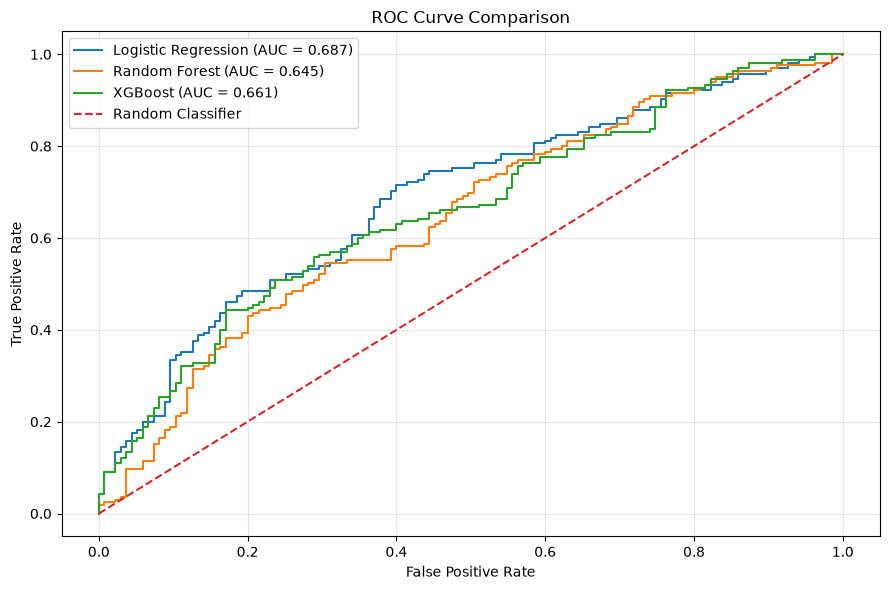


CLASSIFICATION THRESHOLD TUNING
------------------------------------------------------------
Best baseline model: Logistic Regression
Chosen threshold: 0.498
Threshold precision: 0.6596
Threshold recall: 0.7515

Threshold Confusion Matrix:
[[ 71  64]
 [ 41 124]]

RANDOM FOREST GRID SEARCH
------------------------------------------------------------
Fitting 3 folds for each of 12 candidates, totalling 36 fits

Random Forest Best Parameters:
{'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 200}

Random Forest Best CV F1 Score:
0.6855

Tuned Random Forest Validation F1:
0.6846

XGBOOST RANDOMIZED SEARCH
------------------------------------------------------------
Fitting 3 folds for each of 15 candidates, totalling 45 fits

XGBoost Best Parameters:
{'classifier__subsample': 0.7, 'classifier__n_estimators': 100, 'classifier__max_depth': 5, 'classifier__learning_rate': 0.01, 'classifier__colsample_bytree': 0.9}

XGBoost Best CV F1 Score:
0.6723

T

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV,
    StratifiedKFold
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyRegressor

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from xgboost import XGBClassifier

np.random.seed(42)
n = 2000

age = np.random.randint(21, 65, n)
income = np.random.randint(20000, 150001, n)
credit_score = np.random.randint(300, 851, n)
loan_term = np.random.choice([12, 24, 36, 48, 60], n)
employment_years = np.random.randint(0, 31, n)

previous_defaults = np.random.choice(
    [0, 1, 2, 3], n, p=[0.72, 0.18, 0.07, 0.03]
)

employment_type = np.random.choice(
    ["Salaried", "Self-employed", "Business", "Contract"], n
)

marital_status = np.random.choice(
    ["Single", "Married", "Divorced"], n
)

education = np.random.choice(
    ["High School", "Graduate", "Postgraduate"], n
)

application_date = pd.to_datetime(
    np.random.choice(
        pd.date_range("2022-01-01", "2025-12-31"), n
    )
)

loan_amount = (
    income * np.random.uniform(0.25, 1.15, n)
    + (credit_score - 300) * 35
    + loan_term * 180
    + np.random.normal(0, 5000, n)
)

loan_amount = np.clip(loan_amount, 5000, 200000)

risk_score = (
    -0.0035 * (credit_score - 600)
    + 0.000012 * (loan_amount - 50000)
    + 0.55 * previous_defaults
    - 0.025 * employment_years
    + np.random.normal(0, 0.45, n)
)

default_probability = 1 / (1 + np.exp(-risk_score))
loan_default = np.random.binomial(1, default_probability)

data = pd.DataFrame({
    "age": age,
    "income": income,
    "credit_score": credit_score,
    "loan_amount": loan_amount,
    "loan_term": loan_term,
    "employment_years": employment_years,
    "previous_defaults": previous_defaults,
    "employment_type": employment_type,
    "marital_status": marital_status,
    "education": education,
    "application_date": application_date,
    "loan_default": loan_default
})

for column in [
    "income",
    "credit_score",
    "employment_years",
    "employment_type"
]:
    missing_indices = data.sample(
        frac=0.03, random_state=42
    ).index

    data.loc[missing_indices, column] = np.nan

print("DATASET INFORMATION")
print("-" * 60)

print("Dataset shape:", data.shape)
print("Number of records:", len(data))
print("\nFirst five rows:")
print(data.head())

print("\nMissing values:")
print(data.isnull().sum())

print("\nCLASS DISTRIBUTION")
print("-" * 60)

class_counts = data["loan_default"].value_counts().sort_index()
class_percentages = (
    data["loan_default"].value_counts(normalize=True).sort_index() * 100
)

print("Class counts:")
print(class_counts)

print("\nClass percentages:")
print(class_percentages.round(2))

print("\nIMBALANCED DATA EXPLANATION")

print("Accuracy can be misleading when one class has many more records.")
print("A model may predict the majority class and still achieve high accuracy.")
print("Precision measures how many predicted defaults were correct.")
print("Recall measures how many actual defaults were identified.")
print("F1-score balances precision and recall.")

print("\nDATE FEATURE ENGINEERING")
print("-" * 60)

data["application_month"] = data["application_date"].dt.month
data["application_year"] = data["application_date"].dt.year

data.drop(columns=["application_date"], inplace=True)

print("Created application_month and application_year.")
print(data[["application_month", "application_year"]].head())

print("\nCLASSIFICATION DATA SPLITTING")
print("-" * 60)

X = data.drop(columns=["loan_default"])
y = data["loan_default"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training data:", X_train.shape)
print("Validation data:", X_val.shape)
print("Testing data:", X_test.shape)

print("\nPREPROCESSING")
print("-" * 60)

numeric_columns = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numeric columns:", numeric_columns)
print("Categorical columns:", categorical_columns)

def create_preprocessor():

    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, numeric_columns),
            ("categorical", categorical_pipeline, categorical_columns)
        ]
    )

print("Preprocessing pipeline created successfully.")

print("\nCLASSIFICATION MODELS")
print("-" * 60)

classification_models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", LogisticRegression(max_iter=2000))
    ]),

    "Decision Tree": Pipeline(steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", DecisionTreeClassifier(
            max_depth=6,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline(steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=10,
            random_state=42,
            n_jobs=1
        ))
    ]),

    "XGBoost": Pipeline(steps=[
        ("preprocessor", create_preprocessor()),
        ("classifier", XGBClassifier(
            n_estimators=200,
            max_depth=4,
            learning_rate=0.05,
            eval_metric="logloss",
            random_state=42,
            n_jobs=1
        ))
    ])
}

classification_results = []
validation_predictions = {}
validation_probabilities = {}

for name, model in classification_models.items():

    print("\nTraining:", name)

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    validation_predictions[name] = predictions
    validation_probabilities[name] = probabilities

    classification_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_val, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_val,
        predictions,
        zero_division=0
    ))

classification_results_df = pd.DataFrame(classification_results)

print("\nCLASSIFICATION MODEL COMPARISON")
print("-" * 60)

print(classification_results_df.round(4).to_string(index=False))

print("\nROC CURVES AND AUC")
print("-" * 60)

roc_models = [
    "Logistic Regression",
    "Random Forest",
    "XGBoost"
]

plt.figure(figsize=(9, 6))

for name in roc_models:

    probabilities = validation_probabilities[name]

    fpr, tpr, thresholds = roc_curve(
        y_val,
        probabilities
    )

    auc_value = roc_auc_score(
        y_val,
        probabilities
    )

    print(name, "AUC:", round(auc_value, 4))

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_value:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    "task4_roc_curve_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("\nCLASSIFICATION THRESHOLD TUNING")
print("-" * 60)

best_baseline_name = classification_results_df.sort_values(
    by="F1 Score",
    ascending=False
).iloc[0]["Model"]

print("Best baseline model:", best_baseline_name)

threshold_probabilities = validation_probabilities[
    best_baseline_name
]

precisions, recalls, thresholds = precision_recall_curve(
    y_val,
    threshold_probabilities
)

eligible_indices = np.where(recalls[:-1] >= 0.75)[0]

if len(eligible_indices) > 0:

    best_threshold_index = eligible_indices[
        np.argmax(precisions[:-1][eligible_indices])
    ]

    chosen_threshold = thresholds[best_threshold_index]

    threshold_predictions = (
        threshold_probabilities >= chosen_threshold
    ).astype(int)

    threshold_precision = precision_score(
        y_val,
        threshold_predictions,
        zero_division=0
    )

    threshold_recall = recall_score(
        y_val,
        threshold_predictions,
        zero_division=0
    )

    print("Chosen threshold:", round(chosen_threshold, 4))
    print("Threshold precision:", round(threshold_precision, 4))
    print("Threshold recall:", round(threshold_recall, 4))

    print("\nThreshold Confusion Matrix:")
    print(confusion_matrix(y_val, threshold_predictions))

else:

    chosen_threshold = 0.5
    print("No threshold achieved the required recall.")
    print("Using default threshold:", chosen_threshold)

print("\nRANDOM FOREST GRID SEARCH")
print("-" * 60)

rf_pipeline = Pipeline(steps=[
    ("preprocessor", create_preprocessor()),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

rf_parameter_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [5, 10, None],
    "classifier__min_samples_leaf": [1, 2]
}

cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

rf_grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_parameter_grid,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1
)

rf_grid_search.fit(X_train, y_train)

print("\nRandom Forest Best Parameters:")
print(rf_grid_search.best_params_)

print("\nRandom Forest Best CV F1 Score:")
print(round(rf_grid_search.best_score_, 4))

rf_best_model = rf_grid_search.best_estimator_

rf_tuned_predictions = rf_best_model.predict(X_val)

print("\nTuned Random Forest Validation F1:")
print(round(f1_score(
    y_val,
    rf_tuned_predictions,
    zero_division=0
), 4))

print("\nXGBOOST RANDOMIZED SEARCH")
print("-" * 60)

xgb_pipeline = Pipeline(steps=[
    ("preprocessor", create_preprocessor()),
    ("classifier", XGBClassifier(
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

xgb_parameter_distributions = {
    "classifier__n_estimators": [100, 150, 200, 250, 300],
    "classifier__max_depth": [2, 3, 4, 5, 6],
    "classifier__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

xgb_random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_parameter_distributions,
    n_iter=15,
    scoring="f1",
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_random_search.fit(X_train, y_train)

print("\nXGBoost Best Parameters:")
print(xgb_random_search.best_params_)

print("\nXGBoost Best CV F1 Score:")
print(round(xgb_random_search.best_score_, 4))

xgb_best_model = xgb_random_search.best_estimator_

xgb_tuned_predictions = xgb_best_model.predict(X_val)

print("\nTuned XGBoost Validation F1:")
print(round(f1_score(
    y_val,
    xgb_tuned_predictions,
    zero_division=0
), 4))

print("\nFINAL VALIDATION MODEL COMPARISON")
print("-" * 60)

all_validation_models = {
    **classification_models,
    "Tuned Random Forest": rf_best_model,
    "Tuned XGBoost": xgb_best_model
}

all_validation_results = []

for name, model in all_validation_models.items():

    predictions = model.predict(X_val)

    all_validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_val, predictions, zero_division=0
        )
    })

all_validation_results_df = pd.DataFrame(
    all_validation_results
)

print(all_validation_results_df.round(4).to_string(index=False))

best_model_name = all_validation_results_df.sort_values(
    by="F1 Score",
    ascending=False
).iloc[0]["Model"]

best_model = all_validation_models[best_model_name]

print("\nSelected best classification model:", best_model_name)

print("\nLOAN AMOUNT REGRESSION")
print("-" * 60)

X_reg = data.drop(
    columns=["loan_amount", "loan_default"]
)

y_reg = data["loan_amount"]

X_reg_train, X_reg_val, y_reg_train, y_reg_val = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

reg_numeric_columns = X_reg_train.select_dtypes(
    include=np.number
).columns.tolist()

reg_categorical_columns = X_reg_train.select_dtypes(
    exclude=np.number
).columns.tolist()

def create_regression_preprocessor():

    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, reg_numeric_columns),
            ("categorical", categorical_pipeline, reg_categorical_columns)
        ]
    )

regression_models = {
    "Linear Regression": Pipeline(steps=[
        ("preprocessor", create_regression_preprocessor()),
        ("regressor", LinearRegression())
    ]),

    "Ridge Regression": Pipeline(steps=[
        ("preprocessor", create_regression_preprocessor()),
        ("regressor", Ridge(alpha=1.0))
    ]),

    "Lasso Regression": Pipeline(steps=[
        ("preprocessor", create_regression_preprocessor()),
        ("regressor", Lasso(alpha=10.0, max_iter=10000))
    ])
}

mean_baseline = DummyRegressor(strategy="mean")
mean_baseline.fit(X_reg_train, y_reg_train)

baseline_predictions = mean_baseline.predict(X_reg_val)

regression_results = []

def add_regression_result(name, actual, predictions):

    regression_results.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": np.sqrt(mean_squared_error(actual, predictions)),
        "R2 Score": r2_score(actual, predictions)
    })

add_regression_result(
    "Mean Baseline",
    y_reg_val,
    baseline_predictions
)

regression_predictions = {}

for name, model in regression_models.items():

    model.fit(X_reg_train, y_reg_train)

    predictions = model.predict(X_reg_val)

    regression_predictions[name] = predictions

    add_regression_result(
        name,
        y_reg_val,
        predictions
    )

regression_results_df = pd.DataFrame(regression_results)

print("\nREGRESSION MODEL COMPARISON")
print("-" * 60)

print(regression_results_df.round(4).to_string(index=False))

print("\nREGRESSION METRICS EXPLANATION")

print("MAE: Average absolute difference between actual and predicted values.")
print("RMSE: Penalizes larger prediction errors more heavily.")
print("R2: Measures the proportion of target variation explained by the model.")

print("\nBEST REGRESSION MODEL")
print("-" * 60)

best_regression_row = regression_results_df[
    regression_results_df["Model"] != "Mean Baseline"
].sort_values(
    by="RMSE",
    ascending=True
).iloc[0]

best_regression_name = best_regression_row["Model"]

print("Best regression model:", best_regression_name)
print("Best validation MAE:", round(best_regression_row["MAE"], 2))
print("Best validation RMSE:", round(best_regression_row["RMSE"], 2))
print("Best validation R2:", round(best_regression_row["R2 Score"], 4))

print("\nFINAL CLASSIFICATION TEST EVALUATION")
print("-" * 60)

print("Best model selected using validation F1:", best_model_name)

final_test_predictions = best_model.predict(X_test)

final_test_accuracy = accuracy_score(
    y_test,
    final_test_predictions
)

final_test_precision = precision_score(
    y_test,
    final_test_predictions,
    zero_division=0
)

final_test_recall = recall_score(
    y_test,
    final_test_predictions,
    zero_division=0
)

final_test_f1 = f1_score(
    y_test,
    final_test_predictions,
    zero_division=0
)

print("\nFINAL TEST RESULTS")

print("Accuracy:", round(final_test_accuracy, 4))
print("Precision:", round(final_test_precision, 4))
print("Recall:", round(final_test_recall, 4))
print("F1 Score:", round(final_test_f1, 4))

print("\nFinal Test Confusion Matrix:")
print(confusion_matrix(y_test, final_test_predictions))

print("\nFinal Test Classification Report:")
print(classification_report(
    y_test,
    final_test_predictions,
    zero_division=0
))

print("\nSAVED PNG FILES")
print("-" * 60)

print("task4_roc_curve_comparison.png")

